# Xây dựng dataset tin tức VietNamNet

**CO5087 – Cách tiếp cận hiện đại trong xử lý ngôn ngữ tự nhiên**

Notebook thu thập tin từ 20 chuyên mục, xác định nhãn của từng bài và xuất dataset sạch.
Danh sách URL và nội dung được đồng bộ theo nhãn chính của bài viết, phục vụ huấn luyện PhoBERT.


## Thực thi

Chọn Python 3.14 trên máy và bấm **Run All**. Notebook thu thập tối đa 500 trang
cho mỗi chuyên mục, tải nội dung và xác minh nhãn song song, sau đó xuất dataset sạch.

Đầu ra trong `dataset/` gồm 20 Parquet và bốn JSON:
- `data_URLs_raw.json`: URL đầu vào theo chuyên mục nguồn.
- `data_URLs_removed.json`: URL bị loại, URL canonical trùng và lý do xử lý.
- `data_URLs_meta.json`: cấu hình, hash, số lượng và thống kê làm sạch.
- `data_URLs_clean.json`: URL canonical sạch theo nhãn đã xác minh.

Trước chuẩn hóa, số lượng được đọc từ URL gốc; sau chuẩn hóa, số lượng được đọc từ
URL sạch và đối chiếu với Parquet. Checkpoint SQLite chỉ phục vụ tiếp tục quá trình
thu thập, được dọn sau kiểm tra toàn vẹn. Tiến độ cập nhật trên một dòng văn bản;
mỗi biểu đồ hiển thị riêng và được xuất thành PNG 300 dpi.

## Quy trình

**Cấu hình → Thu thập URL → Tải bài và xác định class → Chuẩn hóa dataset → Kiểm tra toàn vẹn → Xuất thống kê**

Nhãn huấn luyện phản ánh chuyên mục trên bài viết; chuyên mục của trang danh sách
chỉ là nơi phát hiện URL. Đường dẫn mục con và đường dẫn chuyên mục có dấu `/`
được xử lý theo cây chuyên mục, không suy nhãn từ nội dung bằng từ khóa.


---
## Chuẩn bị môi trường


In [1]:
import os
import sys
import json
import time
import datetime
import asyncio
import importlib.util
import hashlib
from pathlib import Path
from urllib.parse import urljoin, urlparse

NOTEBOOK_FILENAME = "Dataset_VietNamNet.ipynb"
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / NOTEBOOK_FILENAME).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook từ thư mục chứa notebook hoặc thư mục con.")
RUN_ROOT = PROJECT_ROOT
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

REQUIRED = {
    "requests": "requests",
    "bs4": "beautifulsoup4",
    "lxml": "lxml",
    "pyarrow": "pyarrow",
    "aiohttp": "aiohttp",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "trafilatura": "trafilatura",
    "readability": "readability-lxml",
    "goose3": "goose3",
    "newspaper": "newspaper3k",
    "lxml_html_clean": "lxml_html_clean",
}
missing = [
    package
    for module, package in REQUIRED.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    raise ImportError("Môi trường thiếu thư viện: " + ", ".join(missing))

import aiohttp
import requests
import pyarrow as pa
import pyarrow.parquet as pq
from bs4 import BeautifulSoup

print(f"# Môi trường Python {sys.version.split()[0]} sẵn sàng.")

# Môi trường Python 3.14.7 sẵn sàng.


In [2]:
# Cấu hình thu thập dữ liệu.
MAX_PAGES = 500
NUM_WORKERS = 32
MAX_CRAWL_PASSES = 3
END_CONFIRM_PAGES = 3
CRAWLER_VERSION = "vietnamnet-categories"
DATASET_DIR = str(RUN_ROOT / "dataset")
DATA_URLS_PATH = str(Path(DATASET_DIR) / "data_URLs_raw.json")
CLEAN_URLS_PATH = str(Path(DATASET_DIR) / "data_URLs_clean.json")
REMOVED_URLS_PATH = str(Path(DATASET_DIR) / "data_URLs_removed.json")
URL_META_PATH = str(Path(DATASET_DIR) / "data_URLs_meta.json")

CATEGORY_LABELS = {
    "chinh-tri": "Chính trị",
    "thoi-su": "Thời sự",
    "kinh-doanh": "Kinh doanh",
    "dan-toc-ton-giao": "Dân tộc - Tôn giáo",
    "the-thao": "Thể thao",
    "giao-duc": "Giáo dục",
    "the-gioi": "Thế giới",
    "doi-song": "Đời sống",
    "van-hoa-giai-tri": "Văn hóa - Giải trí",
    "suc-khoe": "Sức khỏe",
    "cong-nghe": "Công nghệ",
    "oto-xe-may": "Ô tô - Xe máy",
    "du-lich": "Du lịch",
    "bat-dong-san": "Bất động sản",
    "ban-doc": "Bạn đọc",
    "tuan-viet-nam": "Tuần Việt Nam",
    "nong-thon-moi": "Nông thôn mới",
    "noi-dung-chuyen-de": "Nội dung chuyên đề",
    "dan-toc-thieu-so-va-mien-nui": "Dân tộc thiểu số và miền núi",
    "cong-nghiep-ho-tro": "Công nghiệp hỗ trợ",
}
CATEGORY_PATHS = {key: key for key in CATEGORY_LABELS}
CATEGORY_PATHS["cong-nghiep-ho-tro"] = "hop-tac/cong-nghiep-ho-tro"
CANONICAL_CLASSES = sorted(CATEGORY_LABELS.values())

CATEGORIES = list(CATEGORY_LABELS)
assert len(CATEGORIES) == 20 and len(set(CATEGORY_LABELS.values())) == 20
print(
    f"# Thu thập {len(CATEGORIES)} chuyên mục, tối đa {MAX_PAGES} trang mỗi chuyên mục."
)
print(f"# Tải bài và xác định nhãn bằng {NUM_WORKERS} worker song song.")

# Thu thập 20 chuyên mục, tối đa 500 trang mỗi chuyên mục.
# Tải bài và xác định nhãn bằng 32 worker song song.


In [3]:
Path(DATASET_DIR).mkdir(parents=True, exist_ok=True)
if not Path(DATA_URLS_PATH).exists():
    Path(DATA_URLS_PATH).write_text("{}", encoding="utf-8")
print("# Thư mục dữ liệu sẵn sàng.")

# Thư mục dữ liệu sẵn sàng.


In [4]:
import sys
import time
from IPython import get_ipython
from IPython.display import display


class TextProgress:
    """One plain-text display per process, updated in place without widgets."""

    def __init__(
        self, iterable=None, total=None, desc="Tiến độ", interval=1.0, **kwargs
    ):
        self.iterable = iterable
        self.total = total if total is not None else self._length(iterable)
        self.description = desc.strip().replace("_", " ")
        self.interval = interval
        self.count = 0
        self.started = time.monotonic()
        self.last_print = self.started
        self.closed = False
        self.details = ""
        self.handle = None
        self.last_width = 0
        shell = get_ipython()
        self.in_notebook = (
            shell is not None and getattr(shell, "kernel", None) is not None
        )
        self._print()

    @staticmethod
    def _length(iterable):
        try:
            return len(iterable)
        except (TypeError, AttributeError):
            return None

    def _print(self):
        elapsed = time.monotonic() - self.started
        if self.total is not None and self.total > 0:
            ratio = min(self.count / self.total, 1)
            filled = int(24 * ratio)
            bar = "#" * filled + "-" * (24 - filled)
            status = f"[{bar}] {self.count:,}/{self.total:,} ({ratio:.1%})"
        else:
            status = f"{self.count:,} mục"
        speed = self.count / elapsed if elapsed > 0 else 0
        message = f"# {self.description}: {status} | {elapsed:.0f} giây | {speed:.1f} mục/giây"
        if self.details:
            message += " | " + self.details
        if self.in_notebook:
            content = {"text/plain": message}
            if self.handle is None:
                self.handle = display(content, raw=True, display_id=True)
            else:
                self.handle.update(content, raw=True)
        else:
            print("\r" + message.ljust(self.last_width), end="", flush=True)
            self.last_width = len(message)
        self.last_print = time.monotonic()

    def update(self, amount=1, details=None, force=False):
        self.count += amount
        if details is not None:
            self.details = details
        if force or time.monotonic() - self.last_print >= self.interval:
            self._print()

    def close(self):
        if not self.closed:
            self._print()
            if not self.in_notebook:
                print(flush=True)
            self.closed = True

    def __iter__(self):
        iterable = self.iterable
        if iterable is None:
            raise TypeError("Tiến độ dạng vòng lặp cần một iterable.")
        try:
            for item in iterable:
                yield item
                self.update()
        finally:
            self.close()

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.close()


def log(message, level="INFO"):
    labels = {
        "INFO": "Thông tin",
        "OK": "Hoàn tất",
        "WARN": "Lưu ý",
        "SAVE": "Lưu kết quả",
        "GPU": "Bộ nhớ GPU",
    }
    print(f"# {labels.get(level, level)}: {message}", flush=True)


class timer:
    def __init__(self, label):
        self.label = label

    def __enter__(self):
        self.started = time.monotonic()
        return self

    def __exit__(self, *args):
        log(f"{self.label}: {time.monotonic() - self.started:.1f} giây", "OK")


import asyncio
from contextlib import ExitStack
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path
import sqlite3
import time
from urllib.parse import urljoin, urlparse

import aiohttp
from bs4 import BeautifulSoup
import pyarrow as pa
import pyarrow.parquet as pq


CLEANING_VERSION = "editorial-breadcrumb"
POLICY_SIGNATURE = hashlib.sha256(
    json.dumps(
        [CLEANING_VERSION, CATEGORY_LABELS, CATEGORY_PATHS],
        sort_keys=True,
        ensure_ascii=False,
    ).encode()
).hexdigest()
SCHEMA = pa.schema(
    [
        (key, pa.string())
        for key in [
            "class",
            "url",
            "title",
            "content",
            "source_categories",
            "category_path",
            "category_method",
        ]
    ]
)


def normalize_url(url, base="https://vietnamnet.vn"):
    if not isinstance(url, str) or not url.strip():
        return None
    parsed = urlparse(urljoin(base, url.strip()))
    if parsed.scheme not in {"http", "https"} or parsed.hostname not in {
        "vietnamnet.vn",
        "www.vietnamnet.vn",
    }:
        return None
    return "https://vietnamnet.vn" + (parsed.path.rstrip("/") or "/")


def category_from_url(url):
    url = normalize_url(url)
    if not url:
        return None
    path = urlparse(url).path.strip("/")
    routes = {**CATEGORY_PATHS, "politics_alias": "thoi-su/chinh-tri"}
    for category, route in sorted(
        routes.items(), key=lambda x: len(x[1]), reverse=True
    ):
        if path == route or path.startswith(route + "/"):
            return "chinh-tri" if category == "politics_alias" else category
    return None


def _objects(value):
    if isinstance(value, dict):
        yield value
        for child in value.values():
            yield from _objects(child)
    elif isinstance(value, list):
        for child in value:
            yield from _objects(child)


def resolve_category(soup, article_url):
    """Read JSON-LD before extractors remove scripts; ignore breadcrumb dropdowns."""
    canonical = soup.select_one('link[rel="canonical"]')
    canonical_href = canonical.get("href", "") if canonical else ""
    canonical_url = (
        urljoin(article_url, canonical_href) if isinstance(canonical_href, str) else ""
    )
    # Legacy VietnamNet URLs can redirect to this separate, out-of-scope portal.
    # Its category links use a different host and must never map by path alone.
    if urlparse(
        canonical_url
    ).hostname == "giamngheobenvung.vietnamnet.vn" and soup.select_one("h1"):
        return {
            "status": "outside",
            "category": None,
            "path": canonical_url,
            "method": "canonical_portal",
            "reason": "outside_taxonomy_portal",
            "canonical_url": canonical_url,
            "breadcrumb": [],
        }
    trails = []
    article_nodes = []
    for tag in soup.select('script[type="application/ld+json"]'):
        try:
            document = json.loads(tag.get_text())
        except (ValueError, TypeError):
            continue
        for obj in _objects(document):
            types = obj.get("@type", [])
            types = types if isinstance(types, list) else [types]
            if any(
                t in {"NewsArticle", "Article", "ReportageNewsArticle"} for t in types
            ):
                article_nodes.append(obj)
            if "BreadcrumbList" not in types:
                continue
            items = obj.get("itemListElement", [])
            if not isinstance(items, list):
                continue
            trail = []
            for index, item in enumerate(items):
                if not isinstance(item, dict):
                    continue
                link = item.get("item", "")
                if isinstance(link, dict):
                    link = link.get("@id", link.get("url", ""))
                link = normalize_url(link, article_url)
                if not link:
                    continue
                try:
                    position = int(item.get("position", index + 1))
                except (ValueError, TypeError):
                    position = index + 1
                trail.append(
                    {"position": position, "name": item.get("name", ""), "url": link}
                )
            if trail:
                trails.append(
                    ("jsonld_breadcrumb", sorted(trail, key=lambda x: x["position"]))
                )

    # Only direct links in the detail breadcrumb: the dropdown contains every class.
    header = soup.select_one(".bread-crumb-detail")
    if header:
        trail = []
        for link in header.select(":scope > ul > li > a[href]"):
            url = normalize_url(link.get("href"), article_url)
            if url:
                trail.append(
                    {
                        "position": len(trail) + 1,
                        "name": link.get_text(" ", strip=True),
                        "url": url,
                    }
                )
        if trail:
            trails.append(("visible_breadcrumb", trail))

    decisions = []
    for method, trail in trails:
        matched = [(item, category_from_url(item["url"])) for item in trail]
        matched = [(item, cat) for item, cat in matched if cat]
        category = matched[-1][1] if matched else None
        path = matched[-1][0]["url"] if matched else trail[-1]["url"]
        # A chain containing only Home supplies no category evidence.
        informative = any(urlparse(item["url"]).path != "/" for item in trail)
        decisions.append(
            {
                "category": category,
                "path": path,
                "method": method,
                "breadcrumb": trail,
                "informative": informative,
            }
        )
    meaningful = [d for d in decisions if d["informative"]]
    categories = {d["category"] for d in meaningful}
    if len(categories) > 1:
        return {
            "status": "unresolved",
            "reason": "conflicting_breadcrumbs",
            "evidence": decisions,
        }
    if meaningful:
        decision = meaningful[0]
        return {
            **decision,
            "status": "accepted" if decision["category"] else "outside",
            "reason": "matched_category"
            if decision["category"]
            else "outside_taxonomy",
        }

    # A main section name can resolve a Home-only chain, but never overrides a path.
    aliases = {name: key for key, name in CATEGORY_LABELS.items()}
    aliases.update({"Dân tộc và Tôn giáo": "dan-toc-ton-giao", "Xe": "oto-xe-may"})
    sections = []
    for node in article_nodes:
        section = node.get("articleSection", "")
        sections.extend(section if isinstance(section, list) else [section])
    sections = [s.strip() for s in sections if isinstance(s, str) and s.strip()]
    resolved = {aliases[s] for s in sections if s in aliases}
    if len(resolved) == 1 and all(s in aliases for s in sections):
        category = resolved.pop()
        return {
            "status": "accepted",
            "category": category,
            "path": CATEGORY_PATHS[category],
            "method": "article_section",
            "reason": "matched_category",
            "breadcrumb": [],
        }
    if resolved:
        return {
            "status": "unresolved",
            "reason": "conflicting_sections",
            "evidence": sections,
        }
    # Distinguish a valid article without an in-scope category from an error page.
    if soup.select_one("h1") and (
        article_nodes or soup.select_one(".content-detail-body, .ArticleContent")
    ):
        return {
            "status": "outside",
            "category": None,
            "path": "",
            "method": "article_metadata",
            "reason": "no_in_scope_category",
            "breadcrumb": [],
            "sections": sections,
        }
    return {
        "status": "unresolved",
        "reason": "missing_article_metadata",
        "evidence": decisions,
    }


def atomic_replace(source, destination):
    for attempt in range(7):
        try:
            os.replace(source, destination)
            return
        except PermissionError:
            if attempt == 6:
                raise
            time.sleep(0.05 * 2**attempt)


def write_json_atomic(path, value):
    path = Path(path)
    pending = path.with_name(path.name + f".{os.getpid()}.tmp")
    pending.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    atomic_replace(pending, path)


def _connect(dataset_dir):
    dataset_dir = Path(dataset_dir)
    dataset_dir.mkdir(parents=True, exist_ok=True)
    connection = sqlite3.connect(dataset_dir / "crawl_state.sqlite3", timeout=30)
    connection.row_factory = sqlite3.Row
    connection.executescript("""
        CREATE TABLE IF NOT EXISTS posts (
            request_url TEXT PRIMARY KEY, canonical_url TEXT, status TEXT,
            category TEXT, title TEXT, content TEXT, evidence TEXT, policy TEXT);
        CREATE INDEX IF NOT EXISTS canonical_index ON posts(canonical_url);
        CREATE TABLE IF NOT EXISTS inputs (url TEXT PRIMARY KEY, sources TEXT);
    """)
    return connection


def prepare_inputs(connection, dataset_dir, all_urls):
    sources = {}
    for category in CATEGORY_LABELS:
        for source_url in all_urls.get(category, []):
            url = normalize_url(source_url)
            if not url or not urlparse(url).path.endswith(".html"):
                raise ValueError(f"URL bài viết không hợp lệ: {source_url!r}")
            sources.setdefault(url, set()).add(category)
    # Existing completed Parquet rows also need checking; do not lose an orphaned post.
    for category in CATEGORY_LABELS:
        path = Path(dataset_dir) / f"{category}.parquet"
        if not path.exists():
            continue
        for batch in pq.ParquetFile(path).iter_batches(batch_size=100):
            for row in batch.to_pylist():
                url = normalize_url(row.get("url"))
                if not url:
                    raise ValueError(f"Parquet có URL không hợp lệ: {path.name}")
                sources.setdefault(url, set()).add(category)
                connection.execute(
                    """INSERT INTO posts(request_url, title, content, status)
                    VALUES (?, ?, ?, 'pending') ON CONFLICT(request_url) DO UPDATE SET
                    title=CASE WHEN coalesce(posts.title,'')='' THEN excluded.title ELSE posts.title END,
                    content=CASE WHEN coalesce(posts.content,'')='' THEN excluded.content ELSE posts.content END""",
                    (url, row.get("title", ""), row.get("content", "")),
                )
    with connection:
        connection.execute("DELETE FROM inputs")
        connection.executemany(
            "INSERT INTO inputs VALUES (?, ?)",
            [
                (url, json.dumps(sorted(cats), ensure_ascii=False))
                for url, cats in sources.items()
            ],
        )
    return sources


async def crawl_and_check(
    dataset_dir, all_urls, extractor, headers, workers=32, batch_size=100
):
    """Fetch each unique URL once; checkpoint every batch, including cancellation."""
    directory = Path(dataset_dir)
    if (directory / "data_URLs_meta.json").exists():
        try:
            verified_audit = verify_clean_dataset(directory)
            verified_urls = json.loads(
                (directory / "data_URLs_raw.json").read_text(encoding="utf-8")
            )
            if all_urls == verified_urls:
                print("# Dataset đã xác minh, giữ nguyên nhãn và thống kê nguồn.")
                return {
                    "unique_urls": verified_audit["unique_input_urls"],
                    "pending_errors": 0,
                    "dataset_ready": True,
                }
        except (RuntimeError, OSError, ValueError):
            pass
    connection = _connect(dataset_dir)
    try:
        sources = prepare_inputs(connection, dataset_dir, all_urls)
        pending = [
            row["url"]
            for row in connection.execute(
                """
            SELECT i.url FROM inputs i LEFT JOIN posts p ON p.request_url=i.url
            WHERE p.policy IS NULL OR p.policy!=? OR p.status NOT IN ('accepted','outside','retry_exhausted')
               OR (p.status='accepted' AND (coalesce(p.title,'')='' OR coalesce(p.content,'')=''))
            ORDER BY i.url""",
                (POLICY_SIGNATURE,),
            )
        ]
        print(
            f"# {sum(len(c) for c in sources.values()):,} lượt URL → {len(sources):,} URL duy nhất; "
            f"cần kiểm tra/tải {len(pending):,}, cache hợp lệ {len(sources) - len(pending):,}."
        )
        queue = asyncio.Queue(maxsize=workers * 2)
        progress = TextProgress(
            total=len(pending), desc="Tải bài + kiểm tra chuyên mục"
        )
        finished = 0
        async with aiohttp.ClientSession(
            headers=headers,
            connector=aiohttp.TCPConnector(limit=workers, ssl=True),
            timeout=aiohttp.ClientTimeout(total=15),
        ) as session:

            async def producer():
                for url in pending:
                    await queue.put(url)
                for _ in range(workers):
                    await queue.put(None)

            async def worker():
                nonlocal finished
                while True:
                    url = await queue.get()
                    if url is None:
                        return
                    try:
                        title, content, decision = await extractor(
                            session, url, with_metadata=True
                        )
                        if decision["status"] == "unresolved" or (
                            decision["status"] == "accepted"
                            and (not title or not content)
                        ):
                            await asyncio.sleep(1)
                            title, content, decision = await extractor(
                                session, url, with_metadata=True
                            )
                        status = decision["status"]
                        if status == "accepted" and (not title or not content):
                            status = "unresolved"
                            decision = {
                                **decision,
                                "reason": "missing_title_or_content",
                            }
                        canonical = (
                            normalize_url(decision.get("canonical_url", url)) or url
                        )
                        if status == "accepted" and not urlparse(
                            canonical
                        ).path.endswith(".html"):
                            status = "unresolved"
                            decision = {
                                **decision,
                                "reason": "invalid_canonical_article_url",
                            }
                        # Discard the body of confirmed out-of-scope posts, retaining only an audit reason.
                        if status != "accepted":
                            title = content = ""
                        connection.execute(
                            """INSERT OR REPLACE INTO posts VALUES (?,?,?,?,?,?,?,?)""",
                            (
                                url,
                                canonical,
                                status,
                                decision.get("category"),
                                title,
                                content,
                                json.dumps(decision, ensure_ascii=False),
                                POLICY_SIGNATURE,
                            ),
                        )
                    except Exception as error:
                        connection.execute(
                            """INSERT OR REPLACE INTO posts VALUES (?,?,?,?,?,?,?,?)""",
                            (
                                url,
                                url,
                                "unresolved",
                                None,
                                "",
                                "",
                                json.dumps(
                                    {"reason": type(error).__name__ + ": " + str(error)}
                                ),
                                POLICY_SIGNATURE,
                            ),
                        )
                    finished += 1
                    if finished % batch_size == 0:
                        connection.commit()
                    progress.update(1)

            tasks = [
                asyncio.create_task(producer()),
                *[asyncio.create_task(worker()) for _ in range(workers)],
            ]
            try:
                await asyncio.gather(*tasks)
            finally:
                for task in tasks:
                    if not task.done():
                        task.cancel()
                await asyncio.gather(*tasks, return_exceptions=True)
                connection.commit()
                progress.close()
        unresolved = [
            dict(row)
            for row in connection.execute(
                """
            SELECT i.url, p.evidence FROM inputs i LEFT JOIN posts p ON p.request_url=i.url
            WHERE p.policy IS NULL OR p.policy!=?
               OR p.status NOT IN ('accepted','outside','retry_exhausted')
               OR (p.status='accepted' AND (coalesce(p.title,'')='' OR coalesce(p.content,'')='')) """,
                (POLICY_SIGNATURE,),
            )
        ]
        print(
            f"# Đã kiểm tra {len(sources) - len(unresolved):,}/{len(sources):,}; cần thử lại {len(unresolved):,}."
        )
        return {"unique_urls": len(sources), "pending_errors": len(unresolved)}
    finally:
        connection.commit()
        connection.close()


def discard_failed_urls(dataset_dir, retry_passes):
    """Exclude unverified articles after retries and retain their audit evidence."""
    connection = _connect(dataset_dir)
    try:
        failed = connection.execute(
            """SELECT i.url, i.sources, p.canonical_url, p.evidence
            FROM inputs i LEFT JOIN posts p ON p.request_url=i.url
            WHERE p.policy IS NULL OR p.policy!=?
               OR p.status NOT IN ('accepted','outside','retry_exhausted')
               OR (p.status='accepted' AND (coalesce(p.title,'')='' OR coalesce(p.content,'')=''))
            ORDER BY i.url""",
            (POLICY_SIGNATURE,),
        ).fetchall()
        with connection:
            for row in failed:
                last_failure = (
                    json.loads(row["evidence"])
                    if row["evidence"]
                    else {"reason": "no_article_record"}
                )
                evidence = {
                    "status": "retry_exhausted",
                    "reason": "retry_limit_reached",
                    "retry_passes": retry_passes,
                    "source_categories": json.loads(row["sources"]),
                    "last_failure": last_failure,
                }
                connection.execute(
                    """INSERT OR REPLACE INTO posts VALUES (?,?,?,?,?,?,?,?)""",
                    (
                        row["url"],
                        row["canonical_url"] or row["url"],
                        "retry_exhausted",
                        None,
                        "",
                        "",
                        json.dumps(evidence, ensure_ascii=False),
                        POLICY_SIGNATURE,
                    ),
                )
        return len(failed)
    finally:
        connection.close()


def publish_clean_metadata(dataset_dir, audit=None):
    """Publish four URL artifacts; remove the crawl checkpoint after validation."""
    dataset_dir = Path(dataset_dir)
    if audit is None:
        audit = read_cleaning_audit(dataset_dir)
    raw = json.loads((dataset_dir / "data_URLs_raw.json").read_text(encoding="utf-8"))
    clean = json.loads(
        (dataset_dir / "data_URLs_clean.json").read_text(encoding="utf-8")
    )
    metadata = {
        cat: {
            "version": CRAWLER_VERSION,
            "source_path": CATEGORY_PATHS[cat],
            "max_pages": MAX_PAGES,
            "url_count": len(raw[cat]),
            "clean_url_count": len(clean[cat]),
            "cleaning_version": CLEANING_VERSION,
            "raw_url_sha256": url_digest(raw[cat]),
            "cleaned_url_sha256": url_digest(clean[cat]),
        }
        for cat in CATEGORY_LABELS
    }
    metadata["url_files"] = {
        "raw": "data_URLs_raw.json",
        "removed": "data_URLs_removed.json",
        "clean": "data_URLs_clean.json",
    }
    metadata["dataset_cleaning"] = audit
    write_json_atomic(dataset_dir / "data_URLs_meta.json", metadata)
    verify_clean_dataset(dataset_dir)
    for name in [
        "data_URLs.json",
        "data_URLs_failed.json",
        "dataset_cleaning.json",
        "crawl_audit.json",
        "crawl_state.sqlite3",
        "crawl_state.sqlite3-journal",
        "crawl_state.sqlite3-wal",
        "crawl_state.sqlite3-shm",
    ]:
        (dataset_dir / name).unlink(missing_ok=True)
    return audit


def read_cleaning_audit(dataset_dir):
    dataset_dir = Path(dataset_dir)
    metadata_path = dataset_dir / "data_URLs_meta.json"
    metadata = (
        json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata_path.exists()
        else {}
    )
    audit = metadata.get("dataset_cleaning")
    if audit is None and (dataset_dir / "dataset_cleaning.json").exists():
        audit = json.loads(
            (dataset_dir / "dataset_cleaning.json").read_text(encoding="utf-8")
        )
    if not isinstance(audit, dict):
        raise RuntimeError(
            "Metadata chưa xác nhận dataset sạch; chạy notebook dataset."
        )
    return audit


def finalize_dataset(dataset_dir, url_meta_path):
    """Prepare all replacements first, then publish; completion marker guards training."""
    dataset_dir = Path(dataset_dir)
    connection = _connect(dataset_dir)
    staging = []
    try:
        unresolved = connection.execute(
            """SELECT count(*) FROM inputs i
            LEFT JOIN posts p ON p.request_url=i.url WHERE p.status IS NULL
            OR p.status NOT IN ('accepted','outside','retry_exhausted') OR p.policy IS NULL OR p.policy!=?""",
            (POLICY_SIGNATURE,),
        ).fetchone()[0]
        if unresolved:
            raise RuntimeError(
                f"Còn {unresolved:,} URL lỗi hoặc chưa xác định được metadata. "
                "Chạy lại bước tải và kiểm tra bài; chưa thay URL/Parquet và chưa cho phép train."
            )
        if not connection.execute("SELECT count(*) FROM inputs").fetchone()[0]:
            raise RuntimeError(
                "Không có snapshot URL để làm sạch; chạy bước tải và kiểm tra bài trước."
            )
        cleaned = {cat: [] for cat in CATEGORY_LABELS}
        before = {cat: 0 for cat in CATEGORY_LABELS}
        transitions = {}
        removed = []
        outside_count = failed_count = 0
        seen = {}
        duplicates = 0
        moved = kept = 0
        buffers = {cat: [] for cat in CATEGORY_LABELS}
        paths = {
            cat: dataset_dir / f"{cat}.parquet.cleaning" for cat in CATEGORY_LABELS
        }
        staging.extend(paths.values())
        with ExitStack() as stack:
            writers = {
                cat: stack.enter_context(pq.ParquetWriter(path, SCHEMA))
                for cat, path in paths.items()
            }
            for row in connection.execute("""SELECT p.*, i.sources FROM inputs i
                    JOIN posts p ON p.request_url=i.url ORDER BY p.canonical_url, p.request_url"""):
                sources = json.loads(row["sources"])
                for source in sources:
                    before[source] += 1
                evidence = json.loads(row["evidence"])
                if row["status"] in {"outside", "retry_exhausted"}:
                    outside_count += int(row["status"] == "outside")
                    failed_count += int(row["status"] == "retry_exhausted")
                    removed.append(
                        {
                            "url": row["request_url"],
                            "source_categories": sources,
                            "reason": evidence.get("reason"),
                            "status": row["status"],
                            "retry_passes": evidence.get("retry_passes", 0),
                            "last_failure": evidence.get("last_failure"),
                            "breadcrumb": evidence.get("breadcrumb", []),
                        }
                    )
                    continue
                cat = row["category"]
                if cat not in CATEGORY_LABELS or not row["title"] or not row["content"]:
                    raise RuntimeError(
                        "Bản ghi accepted không có nhãn/nội dung hợp lệ; cần kiểm tra lại."
                    )
                canonical = row["canonical_url"]
                if canonical in seen:
                    if seen[canonical] != cat:
                        raise RuntimeError(
                            f"URL canonical có hai nhãn mâu thuẫn: {canonical}"
                        )
                    duplicates += 1
                    removed.append(
                        {
                            "url": row["request_url"],
                            "source_categories": sources,
                            "canonical_url": canonical,
                            "status": "canonical_duplicate",
                            "reason": "canonical_duplicate_merged",
                            "kept_category": cat,
                        }
                    )
                    continue
                seen[canonical] = cat
                cleaned[cat].append(canonical)
                kept += int(cat in sources)
                moved += int(cat not in sources)
                for source in sources:
                    key = source + " → " + cat
                    transitions[key] = transitions.get(key, 0) + 1
                buffers[cat].append(
                    {
                        "class": cat,
                        "url": canonical,
                        "title": row["title"],
                        "content": row["content"],
                        "source_categories": json.dumps(sources, ensure_ascii=False),
                        "category_path": evidence.get("path", ""),
                        "category_method": evidence.get("method", ""),
                    }
                )
                if len(buffers[cat]) >= 100:
                    writers[cat].write_table(
                        pa.Table.from_pylist(buffers[cat], schema=SCHEMA)
                    )
                    buffers[cat].clear()
            for cat in CATEGORY_LABELS:
                if buffers[cat]:
                    writers[cat].write_table(
                        pa.Table.from_pylist(buffers[cat], schema=SCHEMA)
                    )
        audit = {
            "version": CLEANING_VERSION,
            "policy_signature": POLICY_SIGNATURE,
            "complete": False,
            "checked_at": datetime.now(timezone.utc).isoformat(),
            "before": before,
            "after": {cat: len(urls) for cat, urls in cleaned.items()},
            "unique_input_urls": sum(
                1 for _ in connection.execute("SELECT url FROM inputs")
            ),
            "kept_in_source_class": kept,
            "moved_to_other_class": moved,
            "removed_outside_taxonomy": outside_count,
            "removed_after_retries": failed_count,
            "removed_total": outside_count + failed_count,
            "canonical_duplicates_merged": duplicates,
            "transitions": transitions,
        }
        if sum(audit["after"].values()) + len(removed) != audit["unique_input_urls"]:
            raise RuntimeError("Số URL trước/sau làm sạch không khớp.")

        # Incomplete metadata prevents training during file publication.
        meta_path = Path(url_meta_path)
        metadata = (
            json.loads(meta_path.read_text(encoding="utf-8"))
            if meta_path.exists()
            else {}
        )
        metadata["dataset_cleaning"] = audit
        write_json_atomic(meta_path, metadata)
        for cat, path in paths.items():
            atomic_replace(path, dataset_dir / f"{cat}.parquet")
        raw_urls = {cat: [] for cat in CATEGORY_LABELS}
        for item in connection.execute("SELECT url, sources FROM inputs ORDER BY url"):
            for source in json.loads(item["sources"]):
                raw_urls[source].append(item["url"])
        write_json_atomic(dataset_dir / "data_URLs_raw.json", raw_urls)
        write_json_atomic(dataset_dir / "data_URLs_removed.json", removed)
        write_json_atomic(dataset_dir / "data_URLs_clean.json", cleaned)
        audit["complete"] = True
        for cat in CATEGORY_LABELS:
            (dataset_dir / f"{cat}.parquet.partial").unlink(missing_ok=True)
        connection.close()
        publish_clean_metadata(dataset_dir, audit)
        return cleaned, audit
    finally:
        connection.close()
        for path in staging:
            path.unlink(missing_ok=True)


def url_digest(urls):
    return hashlib.sha256(json.dumps(urls, ensure_ascii=False).encode()).hexdigest()


def verify_clean_dataset(dataset_dir):
    dataset_dir = Path(dataset_dir)
    audit = read_cleaning_audit(dataset_dir)
    if not audit.get("complete") or audit.get("policy_signature") != POLICY_SIGNATURE:
        raise RuntimeError(
            "Dataset chưa làm sạch xong hoặc chính sách nhãn thay đổi; chạy notebook dataset."
        )
    urls = json.loads(
        (dataset_dir / "data_URLs_clean.json").read_text(encoding="utf-8")
    )
    if set(urls) != set(CATEGORY_LABELS) or set(audit.get("after", {})) != set(
        CATEGORY_LABELS
    ):
        raise RuntimeError("Danh sách URL/audit không khớp bộ 20 class hiện tại.")
    raw = json.loads((dataset_dir / "data_URLs_raw.json").read_text(encoding="utf-8"))
    removed = json.loads(
        (dataset_dir / "data_URLs_removed.json").read_text(encoding="utf-8")
    )
    if set(raw) != set(CATEGORY_LABELS):
        raise RuntimeError("URL gốc không khớp bộ chuyên mục.")
    if {cat: len(raw[cat]) for cat in CATEGORY_LABELS} != audit["before"]:
        raise RuntimeError("Số URL gốc không khớp metadata.")
    unique_raw = set().union(*(set(values) for values in raw.values()))
    removed_urls = [row["url"] for row in removed]
    if len(unique_raw) != audit["unique_input_urls"] or len(set(removed_urls)) != len(
        removed_urls
    ):
        raise RuntimeError("URL gốc hoặc URL bị loại bị trùng/sai số lượng.")
    if not set(removed_urls).issubset(unique_raw):
        raise RuntimeError("Danh sách URL bị loại có URL ngoài snapshot đầu vào.")
    statuses = {
        name: sum(row["status"] == name for row in removed)
        for name in ["outside", "retry_exhausted", "canonical_duplicate"]
    }
    if statuses != {
        "outside": audit["removed_outside_taxonomy"],
        "retry_exhausted": audit.get("removed_after_retries", 0),
        "canonical_duplicate": audit["canonical_duplicates_merged"],
    } or sum(statuses.values()) != len(removed):
        raise RuntimeError("Lý do loại URL không khớp thống kê làm sạch.")
    if len(unique_raw) != sum(audit["after"].values()) + len(removed):
        raise RuntimeError("URL gốc, URL sạch và URL bị loại không khớp số lượng.")
    seen = set()
    for cat in CATEGORY_LABELS:
        expected = set(urls.get(cat, []))
        if len(expected) != len(urls.get(cat, [])):
            raise RuntimeError(f"URL trùng trong class {cat}.")
        actual = set()
        for batch in pq.ParquetFile(dataset_dir / f"{cat}.parquet").iter_batches(
            batch_size=1000
        ):
            for row in batch.to_pylist():
                url = row["url"]
                if (
                    row["class"] != cat
                    or url in seen
                    or not row["title"]
                    or not row["content"]
                ):
                    raise RuntimeError(f"Bản ghi sai class/trùng/thiếu nội dung: {url}")
                if not row.get("category_method"):
                    raise RuntimeError(f"Bài chưa có bằng chứng chuyên mục: {url}")
                if category_from_url(row.get("category_path", "")) != cat:
                    raise RuntimeError(f"Đường dẫn chuyên mục không khớp class: {url}")
                if not normalize_url(url) or not urlparse(url).path.endswith(".html"):
                    raise RuntimeError(
                        f"URL sau làm sạch không phải URL bài viết: {url}"
                    )
                seen.add(url)
                actual.add(url)
        if actual != expected or len(actual) != audit["after"].get(cat):
            raise RuntimeError(f"URL, Parquet và số lượng audit không đồng bộ: {cat}.")
    if len(seen) != sum(audit["after"].values()):
        raise RuntimeError("Tổng số bài không khớp audit.")
    return audit

In [5]:
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "vi-VN,vi;q=0.9,en;q=0.8",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
}


def _atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pending = path.with_name(path.name + f".{os.getpid()}.tmp")
    pending.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    for attempt in range(7):
        try:
            os.replace(pending, path)
            break
        except PermissionError:
            if attempt == 6:
                raise
            time.sleep(0.05 * 2**attempt)


last_crawl_details = {}


def get_urls_of_category(category, max_pages=MAX_PAGES, silent=False):
    """Thu thập URL theo phân trang, kiểm soát lỗi tải và lưu phạm vi thu thập."""
    if not isinstance(max_pages, int) or isinstance(max_pages, bool) or max_pages < 1:
        raise ValueError(
            "max_pages phải là số nguyên dương; Giới hạn mặc định là 500 trang."
        )
    session = requests.Session()
    urls = []
    seen = set()
    pages = []
    empty_run = 0
    category_base = "https://vietnamnet.vn/" + CATEGORY_PATHS[category]
    _iter = range(1, max_pages + 1)
    if not silent:
        _iter = TextProgress(_iter, desc=CATEGORY_LABELS[category])
    stop_reason = "configured_page_limit"
    try:
        for page in _iter:
            page_url = category_base if page == 1 else f"{category_base}-page{page - 1}"
            # A transient error is retried instead of silently ending a category.
            for attempt in range(3):
                try:
                    response = session.get(page_url, headers=HEADERS, timeout=10)
                    if response.status_code == 404:
                        if attempt < 2:
                            time.sleep(attempt + 1)
                            continue
                        break
                    response.raise_for_status()
                    break
                except requests.RequestException:
                    if attempt == 2:
                        raise
                    time.sleep(attempt + 1)
            if page == 1:
                if response.status_code == 404:
                    raise RuntimeError(f"Chuyên mục không tồn tại: {page_url}")
                category_base = response.url.split("#")[0].split("?")[0].rstrip("/")
                if urlparse(category_base).hostname not in {
                    "vietnamnet.vn",
                    "www.vietnamnet.vn",
                }:
                    raise RuntimeError(
                        f"Chuyên mục chuyển hướng ra ngoài website: {category_base}"
                    )
            if response.status_code == 404:
                empty_run += 1
                pages.append(
                    {
                        "page": page,
                        "url": page_url,
                        "status": 404,
                        "articles": 0,
                        "new": 0,
                    }
                )
            else:
                if page > 1 and response.url.split("?")[0].rstrip("/") != page_url:
                    raise RuntimeError(
                        f"Phân trang chuyển hướng bất thường: {page_url} -> {response.url}"
                    )
                soup = BeautifulSoup(response.content, "lxml")
                titles = soup.find_all(class_="vnn-title")
                page_seen = set()
                fresh = []
                for title in titles:
                    link = title if title.name == "a" else title.find("a")
                    if not link:
                        continue
                    href = link.get("href", "")
                    if not isinstance(href, str) or not href:
                        continue
                    href = urljoin(category_base, href).split("#")[0].split("?")[0]
                    parsed = urlparse(href)
                    if parsed.scheme not in {
                        "http",
                        "https",
                    } or parsed.hostname not in {
                        "vietnamnet.vn",
                        "www.vietnamnet.vn",
                    }:
                        continue
                    if not parsed.path.endswith(".html"):
                        continue
                    href = "https://vietnamnet.vn" + parsed.path
                    if href in page_seen:
                        continue
                    page_seen.add(href)
                    if href not in seen:
                        seen.add(href)
                        fresh.append(href)
                if not page_seen:
                    valid_empty = (
                        soup.find(class_="main") is not None
                        and soup.find(class_="normal-category") is not None
                        and soup.select_one("[categoryid]") is not None
                    )
                    if not valid_empty or page == 1:
                        raise RuntimeError(
                            f"Không đọc được danh sách bài: {page_url}; không đánh dấu crawl hoàn tất."
                        )
                    empty_run += 1
                else:
                    empty_run = 0
                # A duplicate page is not an empty archive; continue to the next page.
                urls.extend(fresh)
                pages.append(
                    {
                        "page": page,
                        "url": page_url,
                        "status": response.status_code,
                        "articles": len(page_seen),
                        "new": len(fresh),
                    }
                )
            if empty_run >= END_CONFIRM_PAGES:
                stop_reason = "confirmed_empty_archive"
                break
    finally:
        session.close()
    last_crawl_details[category] = {
        "version": CRAWLER_VERSION,
        "source_path": CATEGORY_PATHS[category],
        "max_pages": max_pages,
        "stop_reason": stop_reason,
        "archive_end_confirmed": stop_reason == "confirmed_empty_archive",
        "url_count": len(urls),
        "pages": pages,
    }
    if not silent:
        print(
            f"# {CATEGORY_LABELS[category]}: {len(urls):,} URL từ {len(pages):,} trang; "
            + (
                "hết danh sách bài."
                if stop_reason == "confirmed_empty_archive"
                else "đạt phạm vi thu thập."
            )
        )
    return urls


# Async helpers (aiohttp)
async def _fetch_html_async(session, url):
    """Three attempts for timeouts, throttling and transient HTTP failures."""
    for attempt in range(3):
        try:
            async with session.get(url) as resp:
                resp.raise_for_status()
                return await resp.read(), resp.charset or "utf-8"
        except (aiohttp.ClientError, asyncio.TimeoutError):
            if attempt < 2:
                await asyncio.sleep(1 + attempt)
    return None, None


async def extract_content_async(session, url, with_metadata=False):
    """Phiên bản async của extract_content.
    Tải HTML một lần bằng aiohttp, chia sẻ cho tất cả 5 layer.
    Layer CPU-bound (goose3, newspaper3k) chạy trong thread executor.
    """
    title, content = "", ""
    loop = asyncio.get_event_loop()

    decision = {"status": "unresolved", "reason": "http_fetch_failed"}
    # Fetch HTML một lần duy nhất
    html_bytes, encoding = await _fetch_html_async(session, url)
    html_str = (
        html_bytes.decode(encoding or "utf-8", errors="replace") if html_bytes else None
    )

    # -- 1. BeautifulSoup -----------------------------------------------------
    if html_bytes is not None:
        try:
            soup = BeautifulSoup(html_bytes, "lxml")
            if with_metadata:
                decision = resolve_category(soup, url)
                canonical = soup.select_one('link[rel="canonical"]')
                canonical_href = canonical.get("href", url) if canonical else url
                decision["canonical_url"] = (
                    urljoin(url, canonical_href) if isinstance(canonical_href, str) else url
                )
                if decision["status"] == "outside":
                    return "", "", decision
            for tag in soup(["script", "style", "nav", "footer", "header", "aside"]):
                tag.decompose()
            for sel in [
                "h1.content-detail-title",
                "h1.ArticleTitle",
                "h1.title-detail",
                "h1.title",
                "h1",
            ]:
                el = soup.select_one(sel)
                if el:
                    t = el.get_text(strip=True)
                    if len(t) > 5:
                        title = t
                        break
            for sel in [
                "div.ArticleContent",
                "div.content-detail-body",
                "div.maincontent",
                "div.main-content",
                "article",
                "main",
            ]:
                el = soup.select_one(sel)
                if el:
                    paras = [
                        p.get_text(strip=True)
                        for p in el.find_all("p")
                        if len(p.get_text(strip=True)) > 20
                    ]
                    if paras:
                        content = " ".join(paras)
                        break
            if not content:
                content = " ".join(
                    p.get_text(strip=True)
                    for p in soup.find_all("p")
                    if len(p.get_text(strip=True)) > 30
                )
        except Exception:
            pass

    # -- 2. trafilatura -------------------------------------------------------
    if (not title or not content) and html_str is not None:
        try:
            import trafilatura

            def _traf():
                r = trafilatura.extract(
                    html_str,
                    include_comments=False,
                    include_tables=False,
                    favor_precision=True,
                    output_format="txt",
                )
                m = trafilatura.extract_metadata(html_str)
                return (m.title.strip() if m and m.title else ""), (
                    r.strip() if r else ""
                )

            tt, tc = await loop.run_in_executor(None, _traf)
            if not title:
                title = tt
            if not content:
                content = tc
        except Exception:
            pass

    # -- 3. readability-lxml --------------------------------------------------
    if (not title or not content) and html_str is not None:
        try:

            def _read():
                from readability import Document

                doc = Document(html_str)
                t = (doc.title() or "").strip()
                s_soup = BeautifulSoup(doc.summary(html_partial=True), "lxml")
                paras = [
                    p.get_text(strip=True)
                    for p in s_soup.find_all("p")
                    if len(p.get_text(strip=True)) > 20
                ]
                return t, " ".join(paras)

            rt, rc = await loop.run_in_executor(None, _read)
            if not title and len(rt) > 5:
                title = rt
            if not content:
                content = rc
        except Exception:
            pass

    # -- 4. goose3 (dùng lại html_str, không fetch lại) -----------------------
    if not title or not content:
        try:

            def _goose():
                from goose3 import Goose

                with Goose(
                    {"browser_user_agent": HEADERS["User-Agent"], "request_timeout": 12}
                ) as g:
                    a = (
                        g.extract(raw_html=html_str, url=url)
                        if html_str
                        else g.extract(url=url)
                    )
                    return (a.title or "").strip(), (a.cleaned_text or "").strip()

            gt, gc = await loop.run_in_executor(None, _goose)
            if not title:
                title = gt
            if not content:
                content = gc
        except Exception:
            pass

    # -- 5. newspaper3k (dùng lại html_str, không fetch lại) ------------------
    if not title or not content:
        try:

            def _news():
                from newspaper import Article

                a = Article(url, language="vi")
                if html_str:
                    a.set_html(html_str)
                else:
                    a.download()
                a.parse()
                return (a.title or "").strip(), (a.text or "").strip()

            nt, nc = await loop.run_in_executor(None, _news)
            if not title:
                title = nt
            if not content:
                content = nc
        except Exception:
            pass

    if with_metadata:
        return title.strip(), content.strip(), decision
    return title.strip(), content.strip()

## Thu thập URL gốc

Thu thập URL theo chuyên mục nguồn và lưu vào `dataset/data_URLs_raw.json`.
Metadata cùng hash xác nhận cache có khớp cấu hình 500 trang hay không.
Danh sách gốc được giữ độc lập với URL sạch; giai đoạn này thống kê URL theo
nơi phát hiện bài, chưa coi chuyên mục nguồn là nhãn huấn luyện.


In [6]:
# Tái sử dụng danh sách URL khi cấu hình và số lượng khớp nhau.
all_urls = json.loads(Path(DATA_URLS_PATH).read_text(encoding="utf-8"))
url_meta = (
    json.loads(Path(URL_META_PATH).read_text(encoding="utf-8"))
    if Path(URL_META_PATH).exists()
    else {}
)
all_urls = {cat: all_urls.get(cat, []) for cat in CATEGORIES}
url_meta = {cat: url_meta.get(cat, {}) for cat in CATEGORIES}


def _url_cache_valid(cat):
    metadata = url_meta[cat]
    return (
        (bool(all_urls[cat]) or metadata.get("cleaning_version") == CLEANING_VERSION)
        and metadata.get("version") == CRAWLER_VERSION
        and metadata.get("source_path") == CATEGORY_PATHS[cat]
        and metadata.get("max_pages") == MAX_PAGES
        and metadata.get("url_count") == len(all_urls[cat])
        and (
            not metadata.get("cleaning_version")
            or metadata.get("raw_url_sha256") == url_digest(all_urls[cat])
        )
    )


pending_categories = [cat for cat in CATEGORIES if not _url_cache_valid(cat)]
for index, cat in enumerate(pending_categories, 1):
    print(f"# Chuyên mục {index}/{len(pending_categories)}: {CATEGORY_LABELS[cat]}")
    all_urls[cat] = get_urls_of_category(cat, max_pages=MAX_PAGES)
    url_meta[cat] = last_crawl_details[cat]
    _atomic_json(DATA_URLS_PATH, all_urls)
    _atomic_json(URL_META_PATH, url_meta)
if not pending_categories:
    print("# URL gốc hợp lệ, sẵn sàng tải và kiểm tra bài viết.")
for cat in CATEGORIES:
    print(f"# URL gốc — {CATEGORY_LABELS[cat]}: {len(all_urls[cat]):,} URL.")

# Chuyên mục 1/20: Chính trị


# Chính trị: [########################] 500/500 (100.0%) | 40 giây | 12.5 mục/giây

# Chính trị: 12,505 URL từ 500 trang; đạt phạm vi thu thập.
# Chuyên mục 2/20: Thời sự


# Thời sự: [########################] 500/500 (100.0%) | 40 giây | 12.6 mục/giây

# Thời sự: 12,506 URL từ 500 trang; đạt phạm vi thu thập.
# Chuyên mục 3/20: Kinh doanh


...

# Nội dung chuyên đề: 12,506 URL từ 500 trang; đạt phạm vi thu thập.
# Chuyên mục 19/20: Dân tộc thiểu số và miền núi


# Dân tộc thiểu số và miền núi: [##----------------------] 47/500 (9.4%) | 4 giây | 11.0 mục/giây

# Dân tộc thiểu số và miền núi: 1,111 URL từ 48 trang; hết danh sách bài.
# Chuyên mục 20/20: Công nghiệp hỗ trợ


# Công nghiệp hỗ trợ: [##----------------------] 54/500 (10.8%) | 5 giây | 10.0 mục/giây

# Công nghiệp hỗ trợ: 1,302 URL từ 55 trang; hết danh sách bài.
# URL gốc — Chính trị: 12,505 URL.
# URL gốc — Thời sự: 12,506 URL.
# URL gốc — Kinh doanh: 12,487 URL.
# URL gốc — Dân tộc - Tôn giáo: 4,288 URL.
# URL gốc — Thể thao: 12,444 URL.
# URL gốc — Giáo dục: 12,455 URL.
# URL gốc — Thế giới: 12,424 URL.
# URL gốc — Đời sống: 12,410 URL.
# URL gốc — Văn hóa - Giải trí: 12,481 URL.
# URL gốc — Sức khỏe: 12,456 URL.
# URL gốc — Công nghệ: 12,489 URL.
# URL gốc — Ô tô - Xe máy: 12,482 URL.
# URL gốc — Du lịch: 11,348 URL.
# URL gốc — Bất động sản: 12,469 URL.
# URL gốc — Bạn đọc: 12,503 URL.
# URL gốc — Tuần Việt Nam: 11,805 URL.
# URL gốc — Nông thôn mới: 992 URL.
# URL gốc — Nội dung chuyên đề: 12,506 URL.
# URL gốc — Dân tộc thiểu số và miền núi: 1,111 URL.
# URL gốc — Công nghiệp hỗ trợ: 1,302 URL.


---
## Tải bài và kiểm tra chuyên mục

Gộp URL trùng trên toàn bộ chuyên mục, tải HTML một lần cho mỗi bài và đọc breadcrumb
trước khi trích xuất tiêu đề và nội dung. Mục con được quy về class cha trong bộ nhãn;
Dân tộc và Tôn giáo → Sắc màu Việt Nam thuộc class Dân tộc - Tôn giáo.

Tiến độ được lưu theo batch để tiếp tục khi bị gián đoạn. Lỗi tải và metadata mâu thuẫn
được thử lại tối đa 3 lượt. URL vẫn thất bại được loại; bài có chuyên mục
ngoài bộ nhãn không tham gia tập huấn luyện.


In [7]:
# Tải và xác định nhãn cho TOÀN BỘ URL; không đặt giới hạn số bài ở quy trình.
# Retry tự động trong cùng Run All; các bài thành công không bị tải lại.
for _crawl_pass in range(1, MAX_CRAWL_PASSES + 1):
    print(f"# Lượt kiểm tra/tải {_crawl_pass}/{MAX_CRAWL_PASSES}")
    crawl_status = await crawl_and_check(
        DATASET_DIR,
        all_urls,
        extract_content_async,
        HEADERS,
        workers=NUM_WORKERS,
        batch_size=100,
    )
    if not crawl_status["pending_errors"]:
        break
    if _crawl_pass < MAX_CRAWL_PASSES:
        await asyncio.sleep(2 * _crawl_pass)
if crawl_status["pending_errors"]:
    discarded_count = discard_failed_urls(DATASET_DIR, MAX_CRAWL_PASSES)
    crawl_status["removed_after_retries"] = discarded_count
    crawl_status["pending_errors"] = 0
    print(
        f"# Bỏ {discarded_count:,} URL vẫn lỗi sau {MAX_CRAWL_PASSES} lượt; "
        "các URL này không tham gia dataset."
    )
print("# Kiểm tra/tải hoàn tất; tiếp tục chuẩn hóa các bài hợp lệ.")

# Lượt kiểm tra/tải 1/3
# 205,463 lượt URL → 204,280 URL duy nhất; cần kiểm tra/tải 204,280, cache hợp lệ 0.


# Tải bài + kiểm tra chuyên mục: [########################] 204,280/204,280 (100.0%) | 6149 giây | 33.2 mục/giây

# Đã kiểm tra 204,201/204,280; cần thử lại 79.
# Lượt kiểm tra/tải 2/3
# 205,463 lượt URL → 204,280 URL duy nhất; cần kiểm tra/tải 79, cache hợp lệ 204,201.


# Tải bài + kiểm tra chuyên mục: [########################] 79/79 (100.0%) | 16 giây | 4.8 mục/giây

# Đã kiểm tra 204,204/204,280; cần thử lại 76.
# Lượt kiểm tra/tải 3/3
# 205,463 lượt URL → 204,280 URL duy nhất; cần kiểm tra/tải 76, cache hợp lệ 204,204.


# Tải bài + kiểm tra chuyên mục: [########################] 76/76 (100.0%) | 16 giây | 4.9 mục/giây

# Đã kiểm tra 204,204/204,280; cần thử lại 76.
# Bỏ 76 URL vẫn lỗi sau 3 lượt; các URL này không tham gia dataset.
# Kiểm tra/tải hoàn tất; tiếp tục chuẩn hóa các bài hợp lệ.


## Chuẩn hóa nhãn và làm sạch dataset

Breadcrumb xác định nhãn của từng bài; mục con được quy về class cha.
Bài đúng class được giữ, bài thuộc class khác được chuyển cả URL và nội dung.
Bài ngoài bộ nhãn hoặc còn lỗi sau ba lượt thử được loại. Các request cùng URL
canonical được gộp thành một bài; request dư được ghi lý do gộp trong danh sách bị loại.

`data_URLs_raw.json` lưu snapshot đầu vào theo chuyên mục nguồn.
`data_URLs_removed.json` lưu URL không được giữ và bằng chứng xử lý.
`data_URLs_clean.json` chỉ chứa URL canonical sạch, mỗi bài thuộc đúng một class.
`data_URLs_meta.json` lưu cấu hình, số lượng, hash và luồng chuyển class.

Sau chuẩn hóa, bảng thống kê và bước kiểm tra dùng URL sạch để đối chiếu từng dòng
Parquet. Tổng URL đầu vào duy nhất bằng số bài sạch cộng số request bị loại hoặc gộp.
Sau khi kiểm tra thành công, notebook dọn checkpoint SQLite và giữ bốn JSON cùng
20 Parquet. Class rỗng được báo rõ trước khi chuyển sang huấn luyện.

In [8]:
# Đồng bộ toàn bộ URL và nội dung theo nhãn đã kiểm tra.
if crawl_status.get("dataset_ready"):
    all_urls = json.loads(Path(CLEAN_URLS_PATH).read_text(encoding="utf-8"))
    cleaning_audit = publish_clean_metadata(DATASET_DIR)
else:
    all_urls, cleaning_audit = finalize_dataset(DATASET_DIR, URL_META_PATH)
import pandas as pd
from IPython.display import display

_cleaning_counts = pd.DataFrame(
    [
        {
            "Class": CATEGORY_LABELS[cat],
            "URL trước làm sạch": cleaning_audit["before"][cat],
            "URL sạch / bài Parquet": len(all_urls[cat]),
        }
        for cat in CATEGORIES
    ]
)
display(_cleaning_counts)
print(
    f"Giữ đúng class nguồn: {cleaning_audit['kept_in_source_class']:,}; "
    f"chuyển class: {cleaning_audit['moved_to_other_class']:,}; "
    f"loại ngoài bộ nhãn: {cleaning_audit['removed_outside_taxonomy']:,}; "
    f"loại sau 3 lượt thử: {cleaning_audit.get('removed_after_retries', 0):,}; "
    f"gộp URL canonical trùng: {cleaning_audit['canonical_duplicates_merged']:,}."
)
_empty_classes = [CATEGORY_LABELS[cat] for cat in CATEGORIES if not all_urls[cat]]
if _empty_classes:
    raise RuntimeError(
        f"Class rỗng sau làm sạch: {_empty_classes}. Cần bổ sung bài đúng chuyên mục trước khi train."
    )
print("URL và Parquet đã đồng bộ; mỗi bài có một class đã kiểm chứng.")

,Class,URL trước làm sạch,URL sạch / bài Parquet
0,Chính trị,12505,12243
1,Thời sự,12506,12420
2,Kinh doanh,12487,12649
3,Dân tộc - Tôn giáo,4288,3700
4,Thể thao,12444,12401
5,Giáo dục,12455,12261
6,Thế giới,12424,11889
7,Đời sống,12410,11905
8,Văn hóa - Giải trí,12481,12318
9,Sức khỏe,12456,12385


Giữ đúng class nguồn: 199,463; chuyển class: 874; loại ngoài bộ nhãn: 3,866; loại sau 3 lượt thử: 76; gộp URL canonical trùng: 1.
URL và Parquet đã đồng bộ; mỗi bài có một class đã kiểm chứng.


In [9]:
# Kiểm tra số lượng, nhãn, URL và nội dung của toàn bộ dataset.
quality_audit = verify_clean_dataset(DATASET_DIR)
quality_rows = []
for category in CATEGORIES:
    article_count = pq.read_metadata(Path(DATASET_DIR) / f"{category}.parquet").num_rows
    quality_rows.append(
        {"Chuyên mục": CATEGORY_LABELS[category], "Số bài": article_count}
    )
display(pd.DataFrame(quality_rows))
print(f"# Kiểm tra toàn vẹn hoàn tất: {sum(quality_audit['after'].values()):,} bài.")

,Chuyên mục,Số bài
0,Chính trị,12243
1,Thời sự,12420
2,Kinh doanh,12649
3,Dân tộc - Tôn giáo,3700
4,Thể thao,12401
5,Giáo dục,12261
6,Thế giới,11889
7,Đời sống,11905
8,Văn hóa - Giải trí,12318
9,Sức khỏe,12385


# Kiểm tra toàn vẹn hoàn tất: 200,337 bài.


## Thống kê và hình minh họa dataset


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
# Semantic palette: primary data, comparison, improvement, neutral/reference.
CHART_COLORS = {
    "primary": "#0072B2",
    "comparison": "#D55E00",
    "positive": "#009E73",
    "neutral": "#64748B",
    "text": "#172B4D",
    "grid": "#CBD5E1",
    "muted": "#E2E8F0",
}
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 14,
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "axes.labelpad": 8,
        "axes.edgecolor": CHART_COLORS["neutral"],
        "axes.labelcolor": CHART_COLORS["text"],
        "text.color": CHART_COLORS["text"],
        "xtick.color": CHART_COLORS["text"],
        "ytick.color": CHART_COLORS["text"],
        "xtick.labelsize": 12,
        "ytick.labelsize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": CHART_COLORS["grid"],
        "grid.linewidth": 0.6,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "legend.fontsize": 12,
        "legend.frameon": False,
    }
)
classes = CANONICAL_CLASSES
label2id = {label: index for index, label in enumerate(classes)}
N_CLASSES = len(classes)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
    )


def save_figure(fig, root, name):
    """Export one PNG at 300 dpi to results and report assets."""
    if not name or ".." in Path(name).parts or Path(name).is_absolute():
        raise ValueError("Invalid figure name")
    if len([ax for ax in fig.axes if ax.get_label() != "<colorbar>"]) != 1:
        raise ValueError(
            "Each figure must contain one plot (plus an optional colorbar)."
        )
    root = Path(root)
    import textwrap

    # Legends occupy a dedicated strip below the axes, never the data area.
    plot_axes = [ax for ax in fig.axes if ax.get_label() != "<colorbar>"]
    handles, labels = [], []
    for ax in plot_axes:
        old_legend = ax.get_legend()
        if old_legend is not None:
            for text, handle in zip(old_legend.get_texts(), old_legend.legend_handles):
                if text.get_text() not in labels:
                    handles.append(handle)
                    labels.append(text.get_text())
            old_legend.remove()
    for old_legend in list(fig.legends):
        old_legend.remove()
    if handles:
        wrapped = [textwrap.fill(label, width=38) for label in labels]
        columns = min(2, len(handles))
        rows = (len(handles) + columns - 1) // columns
        lines = max(label.count("\n") + 1 for label in wrapped)
        legend_inches = 0.28 * rows * lines + 0.25
        bottom = min(0.34, legend_inches / fig.get_figheight())
        legend = fig.legend(
            handles,
            wrapped,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            ncol=columns,
            columnspacing=1.5,
            handlelength=2.4,
            frameon=False,
        )
        fig.tight_layout(rect=(0, bottom, 1, 1), pad=1.2)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        legend_box = legend.get_window_extent(renderer)
        if any(legend_box.overlaps(ax.get_window_extent(renderer)) for ax in plot_axes):
            raise RuntimeError("Legend overlaps the plot area; increase figure height.")
    else:
        fig.tight_layout(pad=1.2)
    for folder in [root / "result/figures", root / "report/source_latex/assets"]:
        output = folder / name
        output.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output.with_suffix(".png"), dpi=300, bbox_inches="tight")
    manifest = root / "result/figure_manifest.json"
    entries = (
        json.loads(manifest.read_text(encoding="utf-8")) if manifest.exists() else {}
    )
    entries[name] = {
        "source": "Dataset_VietNamNet.ipynb",
        "png": "result/figures/" + name + ".png",
        "report_asset": "report/source_latex/assets/" + name + ".png",
    }
    write_json(manifest, entries)
    plt.show()
    plt.close(fig)


def matrix_figure(matrix, normalized=False):
    matrix = np.asarray(matrix)
    values = (
        matrix / np.maximum(matrix.sum(1, keepdims=True), 1) if normalized else matrix
    )
    fig, ax = plt.subplots(figsize=(10.5, 10))
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=1 if normalized else None)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            if matrix[i, j]:
                label = (
                    f"{100 * values[i, j]:.0f}"
                    if normalized
                    else str(int(values[i, j]))
                )
                ax.text(
                    j,
                    i,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9.5,
                    color="white"
                    if sum(
                        a * b
                        for a, b in zip(
                            im.cmap(im.norm(values[i, j]))[:3], [0.2126, 0.7152, 0.0722]
                        )
                    )
                    < 0.45
                    else CHART_COLORS["text"],
                )
    ax.set(
        xticks=range(len(matrix)),
        yticks=range(len(matrix)),
        xlabel="ID nhãn dự đoán",
        ylabel="ID nhãn dữ liệu",
    )
    fig.colorbar(
        im,
        ax=ax,
        label="Tỷ lệ trong lớp" if normalized else "Số bài báo",
        fraction=0.045,
        pad=0.025,
    )
    return fig


def save_fig(fig, name):
    save_figure(fig, RUN_ROOT, name)
    log("Xuất hình: " + name.rsplit("/", 1)[-1].replace("_", " "), "SAVE")

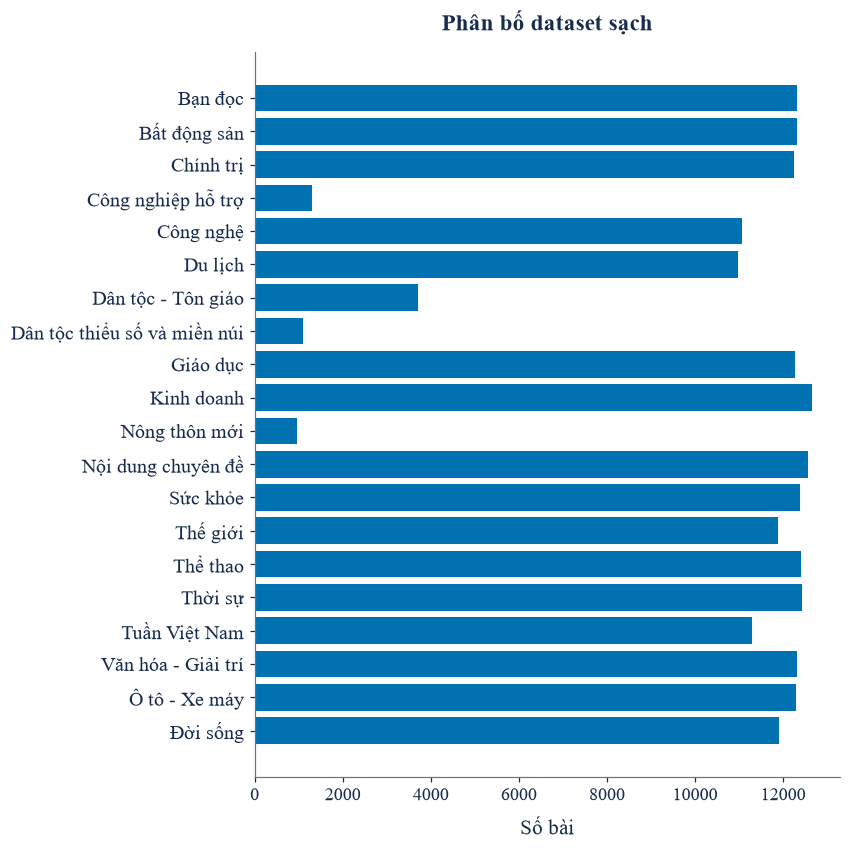

# Lưu kết quả: Xuất hình: clean class distribution


,ID,Chuyên mục
0,0,Bạn đọc
1,1,Bất động sản
2,2,Chính trị
3,3,Công nghiệp hỗ trợ
4,4,Công nghệ
5,5,Du lịch
6,6,Dân tộc - Tôn giáo
7,7,Dân tộc thiểu số và miền núi
8,8,Giáo dục
9,9,Kinh doanh


In [11]:
counts = np.array(
    [
        cleaning_audit["after"][category]
        for label in classes
        for category, name in CATEGORY_LABELS.items()
        if name == label
    ]
)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(N_CLASSES), counts, color=CHART_COLORS["primary"])
ax.set(
    yticks=range(N_CLASSES),
    yticklabels=classes,
    xlabel="Số bài",
    title="Phân bố dataset sạch",
)
ax.invert_yaxis()
save_fig(fig, "dataset/clean_class_distribution")
display(pd.DataFrame({"ID": range(N_CLASSES), "Chuyên mục": classes}))

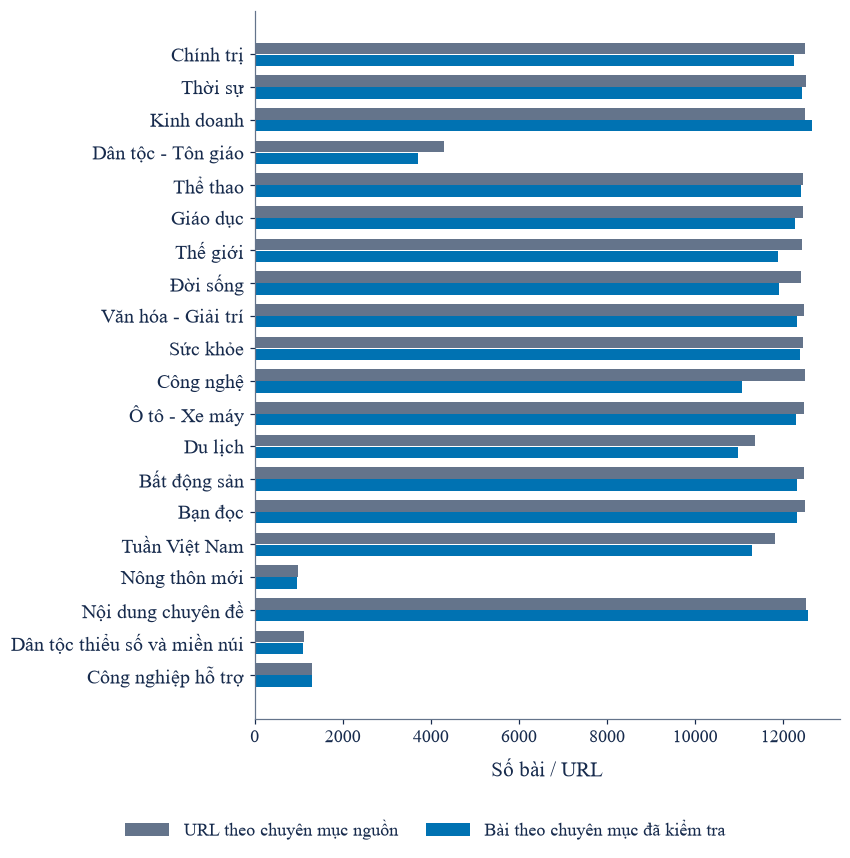

# Lưu kết quả: Xuất hình: class distribution cleaning


In [12]:
# Phân bố dữ liệu trước/sau chuẩn hóa nhãn, mỗi hình xuất riêng.
cleaning_audit = verify_clean_dataset(DATASET_DIR)
_order = list(CATEGORY_LABELS)
_y = np.arange(len(_order))
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(
    _y - 0.18,
    [cleaning_audit["before"][c] for c in _order],
    0.35,
    label="URL theo chuyên mục nguồn",
    color=CHART_COLORS["neutral"],
)
ax.barh(
    _y + 0.18,
    [cleaning_audit["after"][c] for c in _order],
    0.35,
    label="Bài theo chuyên mục đã kiểm tra",
    color=CHART_COLORS["primary"],
)
ax.set(
    yticks=_y, yticklabels=[CATEGORY_LABELS[c] for c in _order], xlabel="Số bài / URL"
)
ax.invert_yaxis()
ax.legend()
save_fig(fig, "dataset/class_distribution_cleaning")

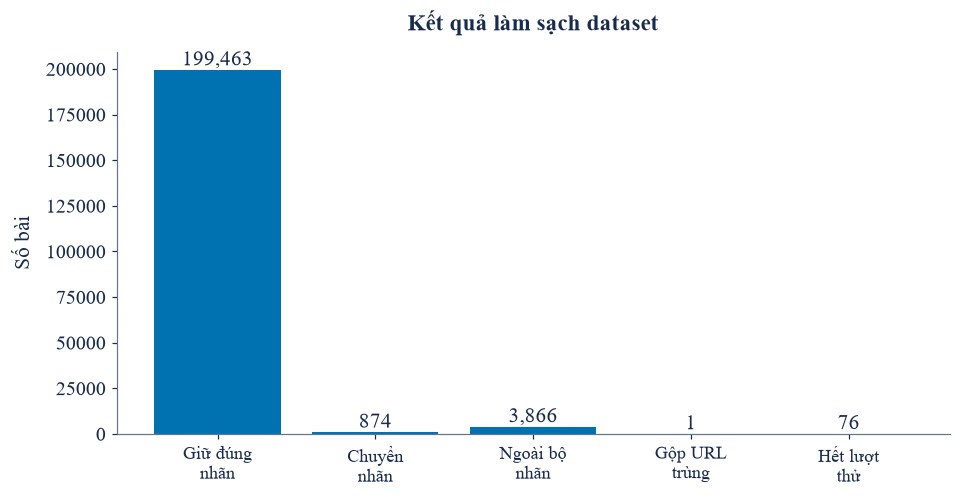

# Lưu kết quả: Xuất hình: cleaning decisions


In [13]:
# Phân bố các quyết định làm sạch dataset.
cleaning_counts = [
    cleaning_audit["kept_in_source_class"],
    cleaning_audit["moved_to_other_class"],
    cleaning_audit["removed_outside_taxonomy"],
    cleaning_audit["canonical_duplicates_merged"],
    cleaning_audit.get("removed_after_retries", 0),
]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(
    [
        "Giữ đúng\nnhãn",
        "Chuyển\nnhãn",
        "Ngoài bộ\nnhãn",
        "Gộp URL\ntrùng",
        "Hết lượt\nthử",
    ],
    cleaning_counts,
    color=CHART_COLORS["primary"],
)
ax.set(ylabel="Số bài", title="Kết quả làm sạch dataset")
for position, value in enumerate(cleaning_counts):
    ax.text(position, value, f"{value:,}", ha="center", va="bottom")
save_fig(fig, "dataset/cleaning_decisions")

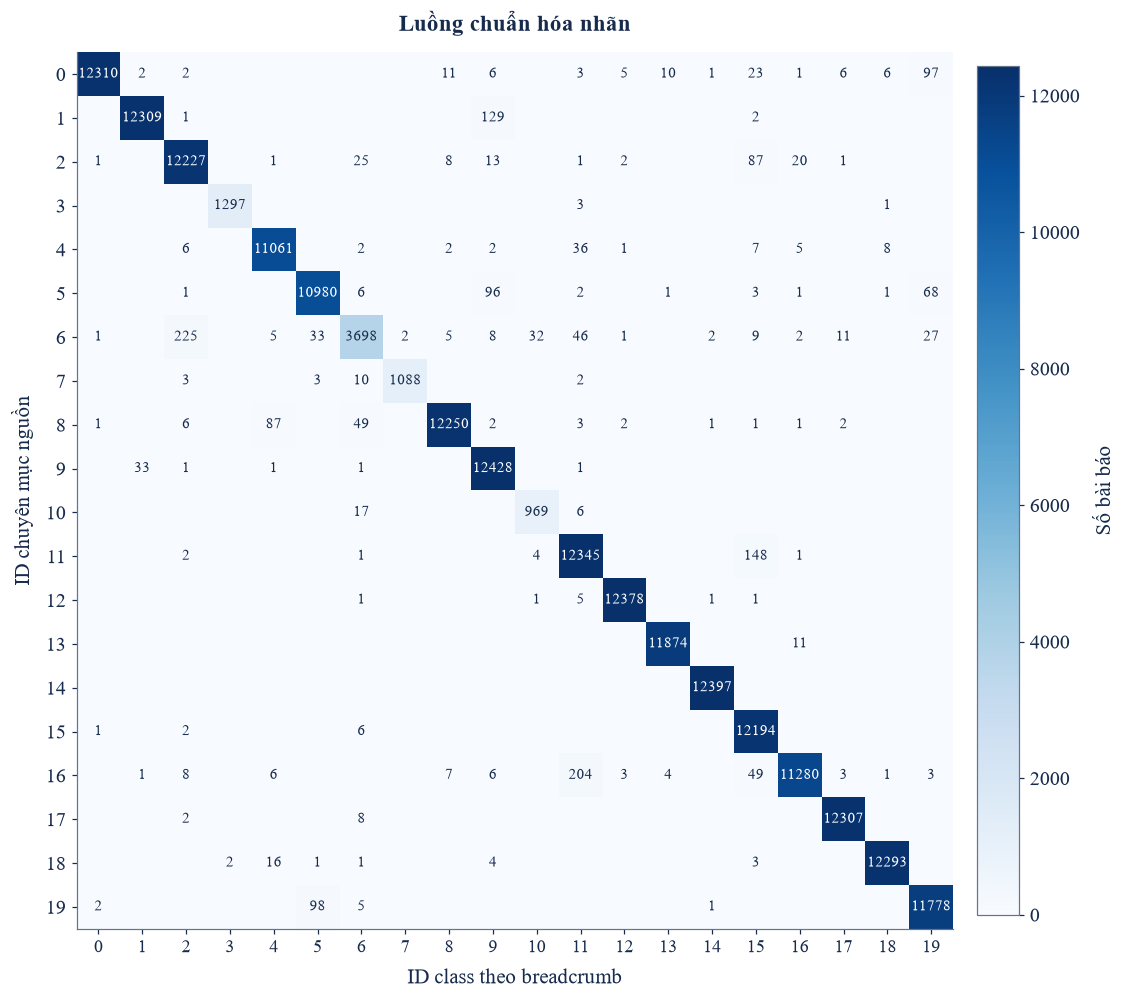

# Lưu kết quả: Xuất hình: cleaning transitions


In [14]:
# Luồng chuyển từ chuyên mục nguồn sang class xác định trên bài.
transition_matrix = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for transition, count in cleaning_audit["transitions"].items():
    source_category, destination_category = transition.split(" → ")
    transition_matrix[
        label2id[CATEGORY_LABELS[source_category]],
        label2id[CATEGORY_LABELS[destination_category]],
    ] += count
fig = matrix_figure(transition_matrix)
fig.axes[0].set(
    xlabel="ID class theo breadcrumb",
    ylabel="ID chuyên mục nguồn",
    title="Luồng chuẩn hóa nhãn",
)
save_fig(fig, "dataset/cleaning_transitions")

In [15]:
verified_dataset = verify_clean_dataset(DATASET_DIR)
print(
    f"# Dataset sạch hoàn tất: {sum(verified_dataset['after'].values()):,} bài, {len(CATEGORIES)} class."
)
print("# URL, Parquet, nhãn và bằng chứng chuyên mục đã được đối chiếu từng bản ghi.")
print("# Sẵn sàng chạy notebook huấn luyện PhoBERT.")
print("# Đầu ra: URL gốc, URL bị loại, metadata, URL sạch và 20 Parquet.")

# Dataset sạch hoàn tất: 200,337 bài, 20 class.
# URL, Parquet, nhãn và bằng chứng chuyên mục đã được đối chiếu từng bản ghi.
# Sẵn sàng chạy notebook huấn luyện PhoBERT.
# Đầu ra: URL gốc, URL bị loại, metadata, URL sạch và 20 Parquet.
